In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Red YOLO

https://github.com/ultralytics/ultralytics

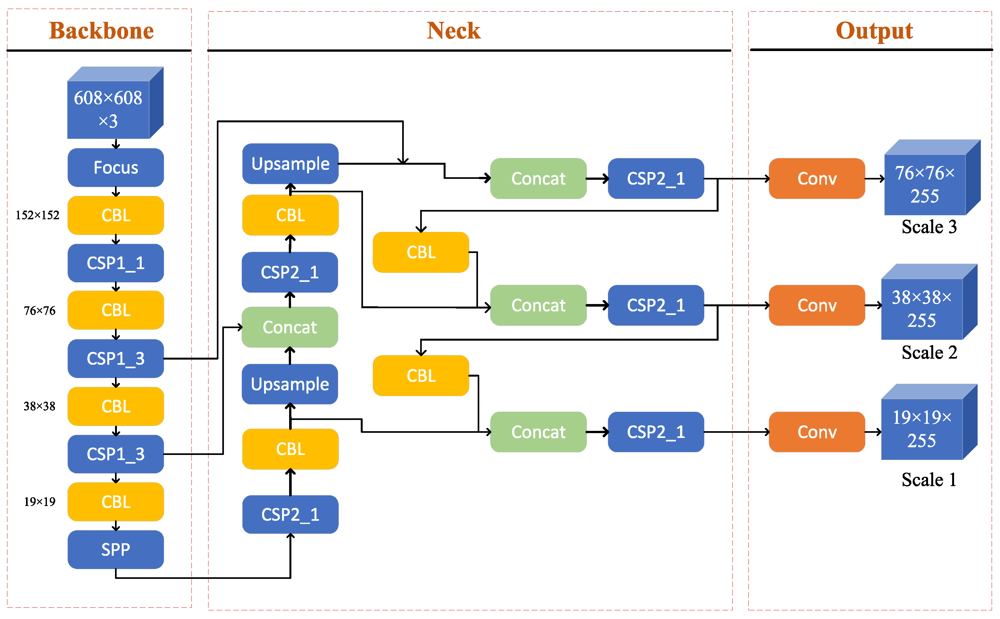

Tomada de: https://www.mdpi.com/2072-4292/13/18/3776/htm

In [ ]:
!nvidia-smi

Sat Oct  3 14:25:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Instalar YOLO26


Para esto vamos a seguir los siguientes pasos:
* Instalar dependencias YOLO
* Descargar datos personalizados de detección de objetos YOLO
* Escribir nuestra configuración de entrenamiento YOLO

**NOTA:** Recuerde elegir GPU en Runtime si aún no está seleccionado.

*Entorno de ejecución --> Cambiar tipo de entorno de ejecución --> Acelerador de hardware --> GPU*)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import requests
from io import BytesIO
import cv2
from google.colab.patches import cv2_imshow

## Instalar dependencias YOLO26


In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.5/95.5 kB 11.3 MB/s eta 0:00:00


In [ ]:
from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/235.7 GB disk)


In [ ]:
from ultralytics import YOLO
#from IPython.display import display, Image

## Cargar el modelo preentrenado

In [ ]:
model = YOLO("yolo26x.pt")

YOLO tiene varias tareas:
- Predecir una imagen o video
- Entrenarse utilizando un conjunto de datos
- Validarse en un conjunto de datos
- Track en videos

```
yolo task=detect    mode=train    model=yolo26n.yaml      args...
          classify       predict        yolo26n-cls.yaml  args...
          segment        val            yolo26n-seg.yaml  args...
                         export         yolo26n.pt        format=onnx  args...
```

## PREDECIR Usando YOLO como está entrenada con COCO

La función detect se puede usar con modelos ya entrenados y los resultados se guardan en *runs/detect*



```
python detect.py --source 0  # webcam (utiliza la cámara)
                          img.jpg  # imagen
                          vid.mp4  # video
                          path/  # directorio de imágenes
                          path/*.jpg  # directorio con extención determinada (hace un glob)
                  --save=True guardar las imágenes con los resultados
                  --save_conf=True guardar imágenes con nivel de confianza
                  --save_txt=True guarda las predicciones como etiquetas
                  --save_crop guardar imágenes cortadas con resultados
                  -- conf nivel de confianza en la predicción
                  -- show mostrar resultados
                  -- show_labels mostrar objetos etiquetados
                  -- boxes mostrar rectángulos en las predicciones
                  -- line_width ancho de la línea de los rectángulos
```

Como resultado se obtiene un generador

In [ ]:
results = model.predict("/content/drive/MyDrive/Fotos_Pruebas/habana.jpg")


image 1/1 /content/drive/MyDrive/Fotos_Pruebas/habana.jpg: 480x640 8 persons, 1 bicycle, 9 cars, 1 motorcycle, 1 bus, 2 trucks, 83.1ms
Speed: 3.8ms preprocess, 83.1ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)


In [ ]:
results

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 

Diccionario con las clases

In [ ]:
results[0].names

{0: 'person',
 1: 'bicycle',
 2: 'car',
 3: 'motorcycle',
 4: 'airplane',
 5: 'bus',
 6: 'train',
 7: 'truck',
 8: 'boat',
 9: 'traffic light',
 10: 'fire hydrant',
 11: 'stop sign',
 12: 'parking meter',
 13: 'bench',
 14: 'bird',
 15: 'cat',
 16: 'dog',
 17: 'horse',
 18: 'sheep',
 19: 'cow',
 20: 'elephant',
 21: 'bear',
 22: 'zebra',
 23: 'giraffe',
 24: 'backpack',
 25: 'umbrella',
 26: 'handbag',
 27: 'tie',
 28: 'suitcase',
 29: 'frisbee',
 30: 'skis',
 31: 'snowboard',
 32: 'sports ball',
 33: 'kite',
 34: 'baseball bat',
 35: 'baseball glove',
 36: 'skateboard',
 37: 'surfboard',
 38: 'tennis racket',
 39: 'bottle',
 40: 'wine glass',
 41: 'cup',
 42: 'fork',
 43: 'knife',
 44: 'spoon',
 45: 'bowl',
 46: 'banana',
 47: 'apple',
 48: 'sandwich',
 49: 'orange',
 50: 'broccoli',
 51: 'carrot',
 52: 'hot dog',
 53: 'pizza',
 54: 'donut',
 55: 'cake',
 56: 'chair',
 57: 'couch',
 58: 'potted plant',
 59: 'bed',
 60: 'dining table',
 61: 'toilet',
 62: 'tv',
 63: 'laptop',
 64: 'mou

In [ ]:
results[0].boxes

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0., 2., 2., 2., 2., 2., 3.], device='cuda:0')
conf: tensor([0.9255, 0.7934, 0.7644, 0.7519, 0.7105, 0.6434, 0.4782], device='cuda:0')
data: tensor([[2.4467e+03, 1.0838e+03, 3.4883e+03, 3.0190e+03, 9.2547e-01, 0.0000e+00],
        [1.5410e+03, 1.3950e+03, 1.8773e+03, 1.5481e+03, 7.9344e-01, 2.0000e+00],
        [8.3566e+02, 1.3779e+03, 1.5375e+03, 1.5762e+03, 7.6436e-01, 2.0000e+00],
        [1.8963e+03, 1.3800e+03, 2.3662e+03, 1.5470e+03, 7.5189e-01, 2.0000e+00],
        [2.3497e+03, 1.3997e+03, 2.5904e+03, 1.5258e+03, 7.1050e-01, 2.0000e+00],
        [3.5310e+03, 1.4008e+03, 3.8189e+03, 1.5001e+03, 6.4335e-01, 2.0000e+00],
        [1.6836e+02, 1.3970e+03, 4.3101e+02, 1.5710e+03, 4.7816e-01, 3.0000e+00]], device='cuda:0')
id: None
is_track: False
orig_shape: (3024, 4032)
shape: torch.Size([7, 6])
xywh: tensor([[2967.4749, 2051.3774, 1041.6201, 1935.2205],
        [1709.1809, 1471.5347,  336.2706,  153.1552],
       

In [ ]:
len(results[0].boxes)

22

Cada objeto detectado (box) en **xyxy**, tiene una clase **cls** y un nivel de confianza de la predicción **conf**

In [ ]:
box=results[0].boxes
x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
(x1, y1), (x2, y2)

((2446, 1083), (3488, 3018))

In [ ]:
box.cls[0]

tensor(0., device='cuda:0')

In [ ]:
results[0].names[int(box.cls[0])]

'person'

In [ ]:
box.conf[0]

tensor(0.9255, device='cuda:0')

In [ ]:
for box in results[0].boxes:
  x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
  cls=results[0].names[int(box.cls[0])]
  conf=round(float(box.conf[0]),2)
  print((x1, y1), (x2, y2), cls, conf)

(2446, 1083) (3488, 3018) person 0.93
(1541, 1394) (1877, 1548) car 0.79
(835, 1377) (1537, 1576) car 0.76
(1896, 1380) (2366, 1546) car 0.75
(2349, 1399) (2590, 1525) car 0.71
(3531, 1400) (3818, 1500) car 0.64
(168, 1396) (431, 1571) motorcycle 0.48


## Mostrar resultados

In [ ]:
x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

In [ ]:
import random
class_names = results[0].names
colors = {}
for cls_name in class_names.values():
  colors[cls_name] = (
    random.randint(0, 255),
    random.randint(0, 255),
    random.randint(0, 255)
  )
colors

{'person': (133, 242, 119),
 'bicycle': (252, 26, 100),
 'car': (163, 242, 37),
 'motorcycle': (251, 191, 102),
 'airplane': (96, 206, 71),
 'bus': (130, 68, 126),
 'train': (159, 75, 167),
 'truck': (178, 220, 3),
 'boat': (108, 97, 43),
 'traffic light': (213, 54, 247),
 'fire hydrant': (73, 241, 23),
 'stop sign': (11, 244, 32),
 'parking meter': (170, 226, 166),
 'bench': (6, 139, 117),
 'bird': (208, 59, 195),
 'cat': (118, 131, 22),
 'dog': (49, 146, 78),
 'horse': (125, 211, 23),
 'sheep': (39, 121, 43),
 'cow': (64, 144, 168),
 'elephant': (185, 165, 149),
 'bear': (96, 233, 93),
 'zebra': (172, 143, 188),
 'giraffe': (217, 195, 252),
 'backpack': (20, 207, 182),
 'umbrella': (251, 59, 198),
 'handbag': (170, 153, 65),
 'tie': (236, 50, 183),
 'suitcase': (214, 226, 42),
 'frisbee': (108, 60, 174),
 'skis': (218, 165, 219),
 'snowboard': (26, 29, 183),
 'sports ball': (146, 232, 22),
 'kite': (84, 79, 161),
 'baseball bat': (31, 10, 202),
 'baseball glove': (95, 25, 108),
 'ska

(2453, 1098) (3488, 3020) person 0.9579
(904, 1394) (1534, 1574) car 0.8985
(2347, 1395) (2602, 1523) car 0.8674
(3530, 1400) (3783, 1504) car 0.862
(1893, 1379) (2371, 1547) truck 0.8611
(0, 1315) (76, 1465) bus 0.815
(1532, 1397) (1877, 1546) car 0.7948
(168, 1431) (431, 1568) motorcycle 0.7546
(840, 1395) (1156, 1563) car 0.7503
(272, 1372) (390, 1536) person 0.686
(712, 1395) (805, 1448) car 0.5423
(925, 1375) (952, 1444) person 0.5026
(3759, 1417) (3830, 1490) car 0.4458
(168, 1431) (432, 1570) bicycle 0.4281
(857, 1374) (892, 1463) person 0.428
(495, 1386) (590, 1428) car 0.3961
(1558, 1396) (1589, 1464) person 0.3779
(622, 1377) (704, 1422) car 0.3638
(873, 1367) (903, 1460) person 0.343
(1242, 1365) (1489, 1443) truck 0.3212
(1584, 1392) (1621, 1453) person 0.312
(2312, 1386) (2357, 1432) person 0.2725


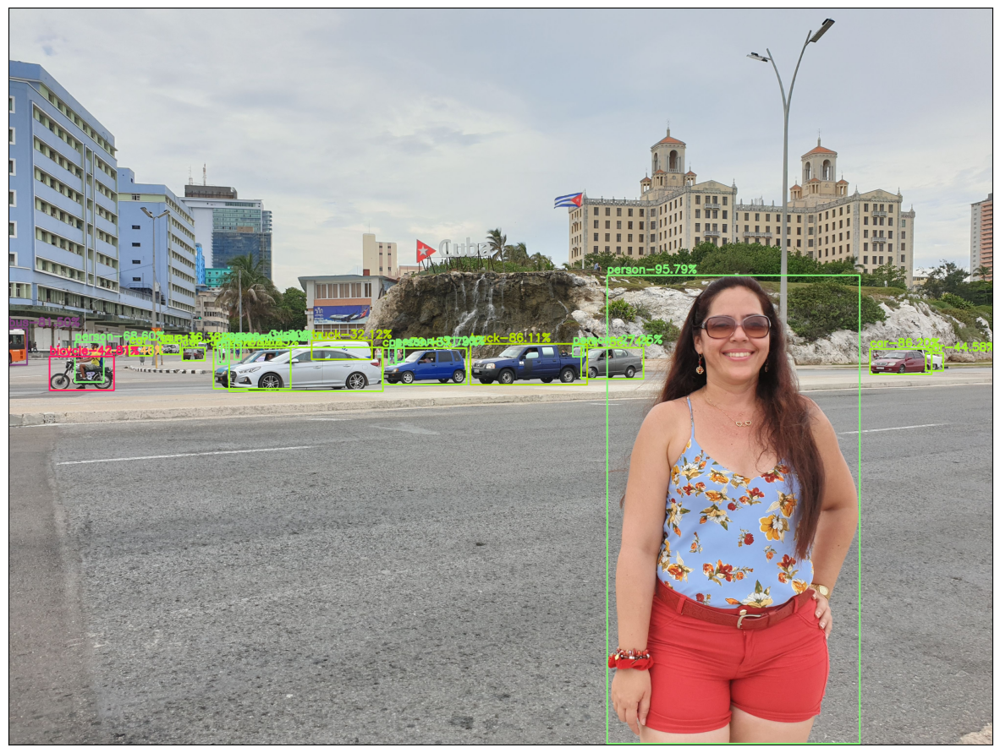

In [ ]:
im=plt.imread("/content/drive/MyDrive/Fotos_Pruebas/habana.jpg").copy()
for box in results[0].boxes:
  x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
  cls=results[0].names[int(box.cls[0])]
  conf=round(float(box.conf[0]),4)
  color=colors[cls]
  print((x1, y1), (x2, y2), cls, conf)
  im=cv2.rectangle(im, (x1, y1), (x2, y2), color, 6)
  im=cv2.putText(im, cls+"-" "{:.2f}".format(conf*100)+"%", (x1,y1-10), cv2.FONT_HERSHEY_SIMPLEX, 1.5, color, 6, cv2.LINE_AA)

plt.figure(figsize=(15,15))
plt.imshow(im)
plt.xticks([])
plt.yticks([])
plt.show()

### Mostrar resultados con el mismo objeto

Ver : https://docs.ultralytics.com/modes/predict/#plotting-results para los parámetros de la función plot

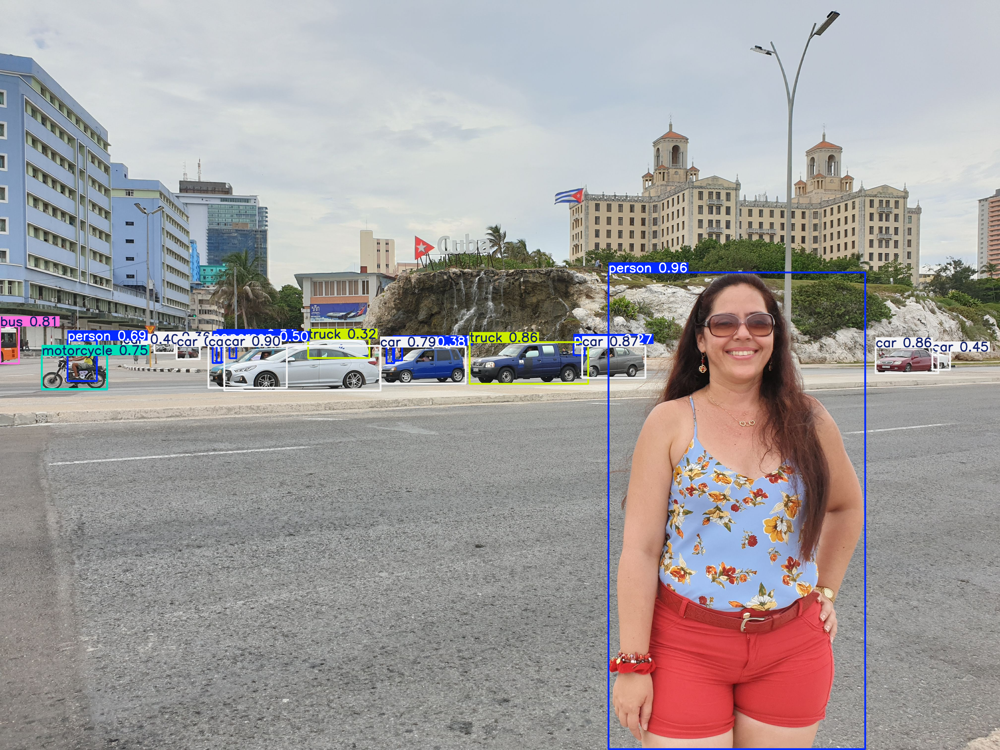

In [ ]:
for r in results:
  im_array = r.plot(line_width=5) # font_size
  im = Image.fromarray(im_array[..., ::-1])  # imagen RGB PIL
  cv2_imshow(im_array)
  im.save('results.jpg')  # guardar image

## Guardando los resultados desde la predicción

In [ ]:
results_2 = model.predict("/content/drive/MyDrive/Fotos_Pruebas/habana.jpg",
                          save=True,show_labels=True, show_boxes=True, save_crop=True, line_width=5)


image 1/1 /content/drive/MyDrive/Fotos_Pruebas/habana.jpg: 480x640 8 persons, 1 bicycle, 9 cars, 1 motorcycle, 1 bus, 2 trucks, 118.9ms
Speed: 3.4ms preprocess, 118.9ms inference, 2.4ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict


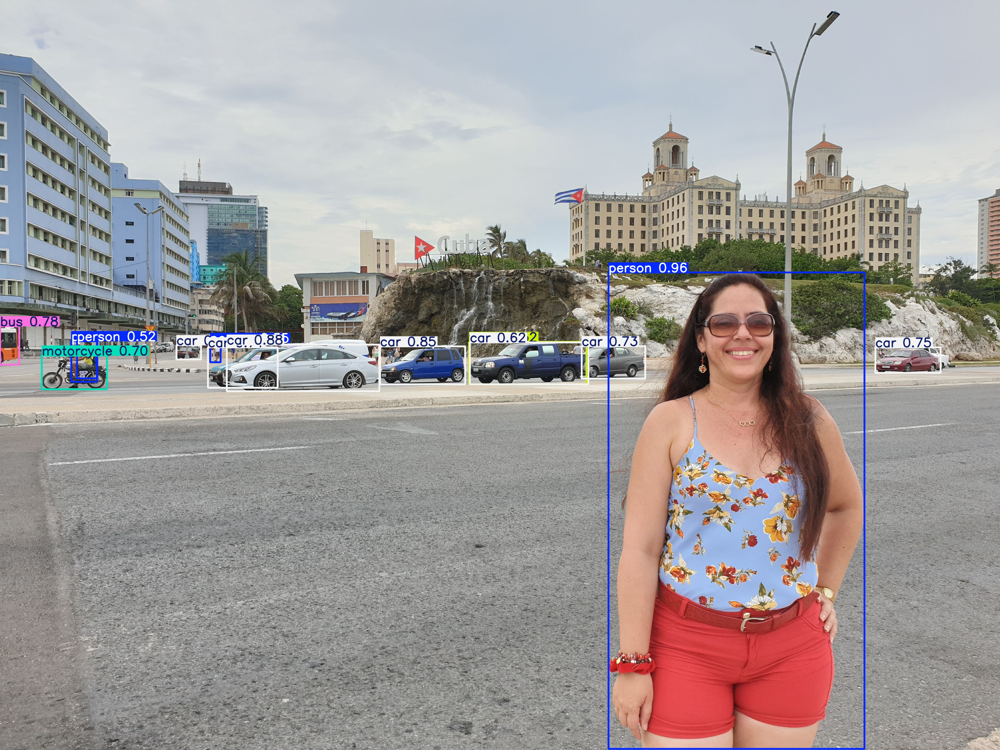

In [ ]:
from IPython.display import Image
Image(filename='/content/runs/detect/predict/habana.jpg', width=800)

## Predecir en video

Descargar un video de ejemplo

In [ ]:
!gdown "https://drive.google.com/uc?id=1hl_NNFciFwImmqplL3RkozpiIa8I38cd&confirm=t"

Downloading...
From: https://drive.google.com/uc?id=1hl_NNFciFwImmqplL3RkozpiIa8I38cd&confirm=t
To: /content/demo.mp4
100% 11.5M/11.5M [00:00<00:00, 48.9MB/s]


In [ ]:
model = YOLO('yolo11m.pt')

In [ ]:
results_video = model.predict("/content/demo.mp4",save=True,show_labels=True, boxes=True)

WARNING ⚠️ 'boxes' is deprecated and will be removed in in the future. Please use 'show_boxes' instead.


WARNING ⚠️ inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/1314) /content/demo.mp4: 384x640 3 cars, 1 truck, 41.8ms
video 1/1 (frame 2/1314) /content/demo.mp4: 384x640 3 cars, 1 truck, 25.4ms
video 1/1 (frame 3/1314) /content/demo.mp4: 384x640 4 cars, 1 truck, 25.3ms
video 1/1 (frame 4/1314) /content/demo.mp4: 384x640 4 cars, 1 truck, 25.3ms
video 1/1 (frame 5/1314) /content/demo.mp4: 384x

In [ ]:
from IPython.display import HTML
from base64 import b64encode
import os

In [ ]:
# Video de salida de predicción
save_path = '/content/runs/detect/predict2/demo.avi'

# Comprimir video
compressed_path = "/content/result_compressed.mp4"

os.system(f"ffmpeg -i {save_path} -vcodec libx264 {compressed_path}")

# Mostrar video
mp4 = open(compressed_path,'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=400 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

## Track un video

In [ ]:
results = model.track(source="/content/demo.mp4", show=True, tracker="bytetrack.yaml",
                      save=True,show_labels=True, boxes=True)

requirements: Ultralytics requirement ['lapx>=0.5.2'] not found, attempting AutoUpdate...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 12.0 MB/s eta 0:00:00

requirements: AutoUpdate success ✅ 4.5s, installed 1 package: ['lapx>=0.5.2']
requirements: ⚠️ Restart runtime or rerun command for updates to take effect

WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()



WARNING ⚠️ inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (1/1314) /content/demo.mp4: 384x640 1 truck, 9

In [ ]:
results[0].save_dir

'runs/detect/predict'

In [ ]:
save_path = '/content/runs/detect/predict/demo.avi'

# Comprimir video
compressed_path = "/content/resultTrack.mp4"

os.system(f"ffmpeg -i {save_path} -vcodec libx264 {compressed_path}")

# Mostrar video
mp4 = open(compressed_path,'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=400 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

## Exportar un modelo

In [ ]:
model.export(format="onnx")

Ultralytics YOLOv8.0.170 🚀 Python-3.10.12 torch-2.0.1+cu118 CPU (Intel Xeon 2.00GHz)

PyTorch: starting from 'yolov8m.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (49.7 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0'] not found, attempting AutoUpdate...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 66.4 MB/s eta 0:00:00

requirements: AutoUpdate success ✅ 9.2s, installed 1 package: ['onnx>=1.12.0']
requirements: ⚠️ Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.14.1 opset 17...


============= Diagnostic Run torch.onnx.export version 2.0.1+cu118 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



ONNX: export success ✅ 14.3s, saved as 'yolov8m.onnx' (99.0 MB)

Export complete (19.8s)
Results saved to /content
Predict:         yolo predict task=detect model=yolov8m.onnx imgsz=640  
Validate:        yolo val task=detect model=yolov8m.onnx imgsz=640 data=coco.yaml  
Visualize:       https://netron.app


'yolov8m.onnx'

# Ejemplo Base de datos BCCD

Si quieres crear tu propia base de datos necesita crear las anotaciones de la misma, o sea identificar las clases dentro de la imagen, para esto puedes usar roboflow: https://docs.roboflow.com/annotate

En este ejemplo vamos a usar la base de datos de ejemplo BCCD: https://public.roboflow.com/object-detection/bccd

En esta base de datos hay 364 imágenes en tres clases: WBC (glóbulos blancos), RBC (glóbulos rojos) y plaquetas. Hay 4888 etiquetas en 3 clases. Son 4155 RBC, 372 WBC y 361 Plaquetas.

Esta base de datos puede ser descargada del *roboflow* directamente usando una API, o puede ser descargada, en este caso para la versión YOLOv5, como haremos en este caso, que la tenemos en Drive.

In [ ]:
!curl -L "https://app.roboflow.com/ds/16C7VJ3F3f?key=Wl9oHHDumY" > BCCD.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   910  100   910    0     0   2330      0 --:--:-- --:--:-- --:--:--  2327
100 12.5M  100 12.5M    0     0  13.2M      0 --:--:-- --:--:-- --:--:-- 13.2M


In [ ]:
!unzip BCCD.zip -d /content/BCCD/

Archive:  BCCD.zip
 extracting: /content/BCCD/README.roboflow.txt  
 extracting: /content/BCCD/data.yaml  
   creating: /content/BCCD/test/
   creating: /content/BCCD/test/images/
 extracting: /content/BCCD/test/images/BloodImage_00038_jpg.rf.2a543ff80a02042a2a048829778ee05b.jpg  
 extracting: /content/BCCD/test/images/BloodImage_00044_jpg.rf.98d6628627331e35a48310d732bc347d.jpg  
 extracting: /content/BCCD/test/images/BloodImage_00062_jpg.rf.46735e3a30f75df2f0abb8b53b67947c.jpg  
 extracting: /content/BCCD/test/images/BloodImage_00090_jpg.rf.801b4d55017cc7fbfc2132855cccf5d4.jpg  
 extracting: /content/BCCD/test/images/BloodImage_00099_jpg.rf.5b8eca0009cca88b2192c24310e7d48d.jpg  
 extracting: /content/BCCD/test/images/BloodImage_00112_jpg.rf.e6c5a6f018bc9f5fb43c1424f5ce1c90.jpg  
 extracting: /content/BCCD/test/images/BloodImage_00113_jpg.rf.bc50ff85b952c24070d2f5aef2e203ae.jpg  
 extracting: /content/BCCD/test/images/BloodImage_00120_jpg.rf.58ae37ce3bc315a44370d37a34a18a21.jpg  
 ext

In [ ]:
#!unzip /content/drive/MyDrive/Datasets/DatasetsAnalytics/HealthData/BCCD.v3-raw.yolov5pytorch.zip -d /content/BCCD/

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import requests
from io import BytesIO
import cv2
from google.colab.patches import cv2_imshow

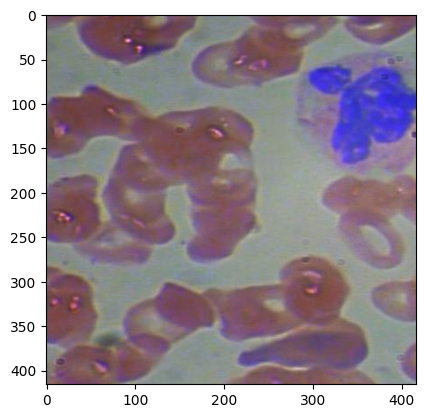

In [ ]:
plt.figure()
img = plt.imread('/content/BCCD/train/images/BloodImage_00001_jpg.rf.5127eaae71c4b12004a977d805672d2a.jpg')
plt.imshow(img)
plt.show()

In [ ]:
img.shape

(416, 416, 3)

In [ ]:
import glob
image_paths=glob.glob('/content/BCCD/train/images/*.jpg')

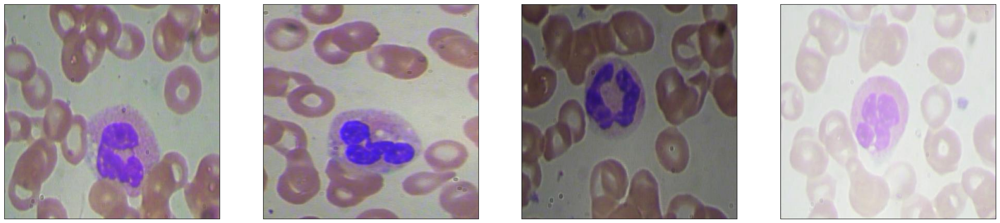

In [ ]:
plt.figure(figsize=(30,60))
for i,imgP in enumerate(image_paths[0:4]):
  ax = plt.subplot(1, 4, i + 1)
  img = plt.imread(imgP)
  plt.imshow(img)
  ax.get_xaxis().set_visible(False)
  ax.get_yaxis().set_visible(False)

In [ ]:
import yaml
with open("/content/BCCD/data.yaml", 'r') as stream:
  num_classes = str(yaml.safe_load(stream)['nc'])

In [ ]:
num_classes

'3'

Si vemos el fichero data.yaml es el que se genera automáticamenten las direcciones de las imágenes de entrenamiento y validación, así como la cantidad y los nombres de las clases.

Para que las direcciones de entrenamiento y validación estén correctas sin necesidad de cambiar los datos de dirección podemos ponerlas fichas. Copiemos las rutas de las mismas y pongámoslas en el fichero de forma que queden así:

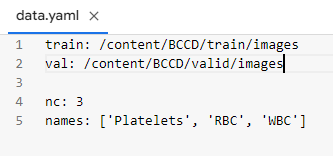



# Entrenar la red YOLO con este ejemplo

Cargar el modelo y pasar los parámetros correspondientes para entrenar con la base de datos

https://docs.ultralytics.com/usage/cfg/#train

In [ ]:
from ultralytics import settings

settings.update({"tensorboard": True})
print(settings["tensorboard"])

In [ ]:
model = YOLO('yolo26m.pt')

In [ ]:
path='/content/Test_YOLO/'
subpath='BCCD'


In [ ]:
results = model.train(data='/content/BCCD/data.yaml', epochs=100, imgsz=416,
                      project=path, # dirección para guardar los resultados
                      name=subpath, # nombre de subdirectorio
                      val=True)

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BCCD/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=BCCD, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

## Evaluar la red

Las pérdidas de entrenamiento y las métricas de rendimiento se guardan en Tensorboard y también en un archivo de registro definido anteriormente con el indicador *--name* cuando entrenamos. En nuestro caso, lo llamamos yolov5s_results. (Si no se le asigna un nombre, el valor predeterminado es *results.txt*). El archivo de resultados se representa como un png una vez que finaliza el entrenamiento.

**Nota de Glenn**: Los archivos *results.txt* parcialmente completados se pueden trazar con *from utils.utils import plot_results; plot_results()*.

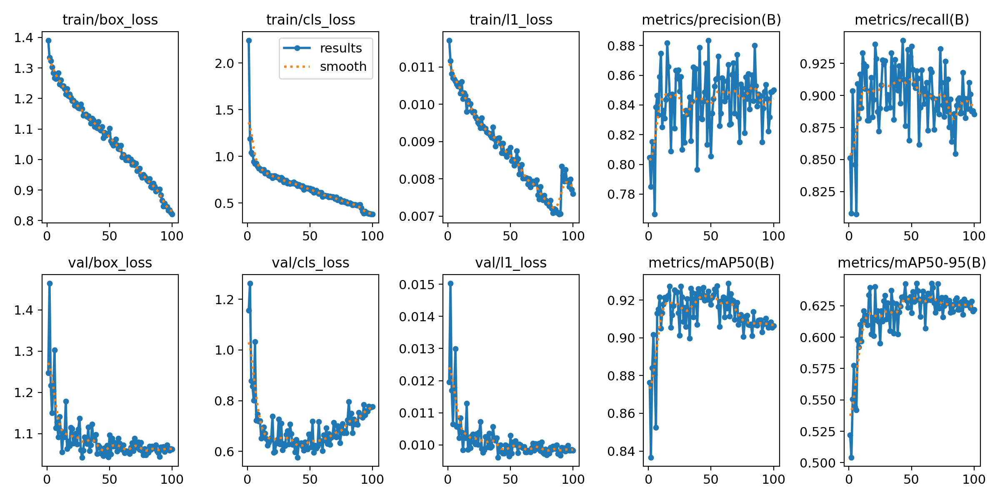

In [ ]:
from IPython.display import Image
Image(filename=path+subpath+'/results.png', width=1000)  # results.png

In [ ]:
logdir = os.path.join(path, subpath)
print(os.listdir(logdir))

['train_batch2.jpg', 'train_batch1.jpg', 'BoxP_curve.png', 'val_batch1_pred.jpg', 'weights', 'confusion_matrix.png', 'val_batch2_pred.jpg', 'args.yaml', 'BoxF1_curve.png', 'results.png', 'val_batch1_labels.jpg', 'train_batch4322.jpg', 'BoxPR_curve.png', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch2_labels.jpg', 'results.csv', 'confusion_matrix_normalized.png', 'train_batch4320.jpg', 'train_batch4321.jpg', 'labels.jpg', 'BoxR_curve.png', 'train_batch0.jpg']


In [ ]:
import os
logdir = os.path.join(path, subpath)
%load_ext tensorboard
%tensorboard --logdir {logdir}

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


<IPython.core.display.Javascript object>

## Visualizar nuestros datos de entrenamiento con etiquetas



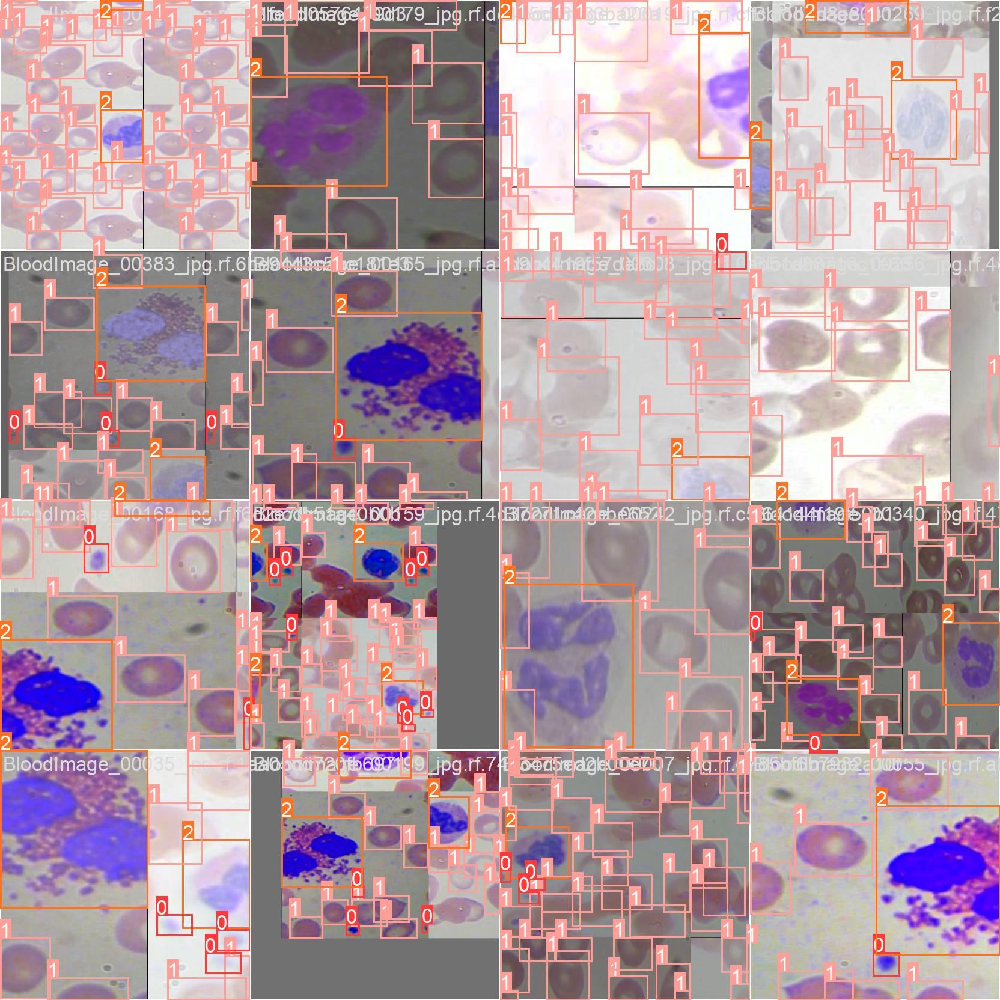

In [ ]:
Image(filename=path+subpath+'/train_batch0.jpg', width=1000)

## Validar el modelo

In [ ]:
model = YOLO('/content/drive/MyDrive/Test_YOLO/BCCD/weights/best.pt')  # load a custom model

In [ ]:
metrics = model.val(plots=True)  # no arguments needed, dataset and settings remembered

Ultralytics YOLOv8.0.168 🚀 Python-3.10.12 torch-2.0.1+cu118 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 168 layers, 11126745 parameters, 0 gradients
val: Scanning /content/BCCD/valid/labels.cache... 73 images, 0 backgrounds, 0 corrupt: 100%|██████████| 73/73 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:11<00:00,  2.27s/it]
                   all         73        967      0.877       0.91      0.936      0.665
             Platelets         73         76      0.869      0.882      0.927      0.547
                   RBC         73        819      0.792       0.85        0.9      0.642
                   WBC         73         72      0.968          1      0.982      0.805
Speed: 2.2ms preprocess, 18.1ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/drive/MyDrive/Test_YOLO/BCCD2


In [ ]:
print(metrics.box.map)    # map50-95
print(metrics.box.map50)  # map50
print(metrics.box.map75)  # map75
print(metrics.box.maps)   # lista map50-95

0.6646255825098549
0.9362969374080098
0.7846188675467589
[     0.5468      0.6416     0.80548]


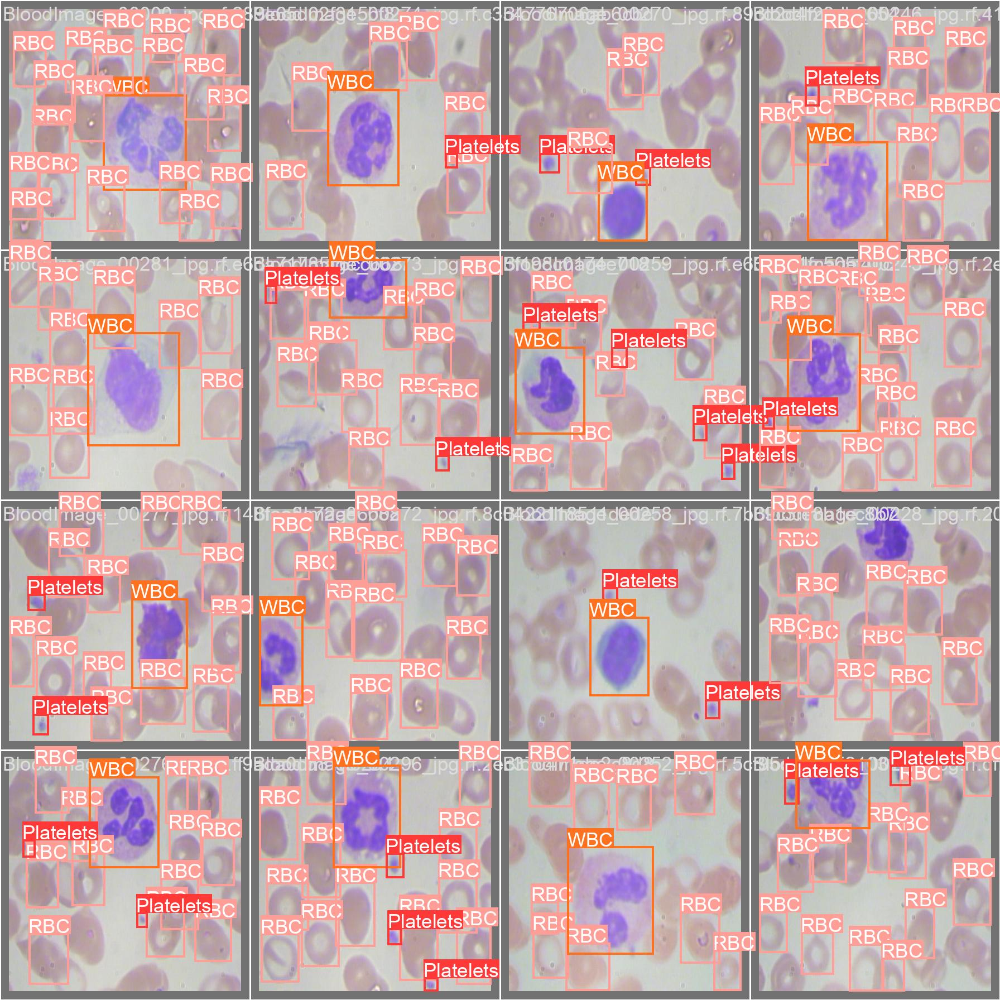

In [ ]:
Image(filename=path+subpath+'2/val_batch0_labels.jpg', width=1000)

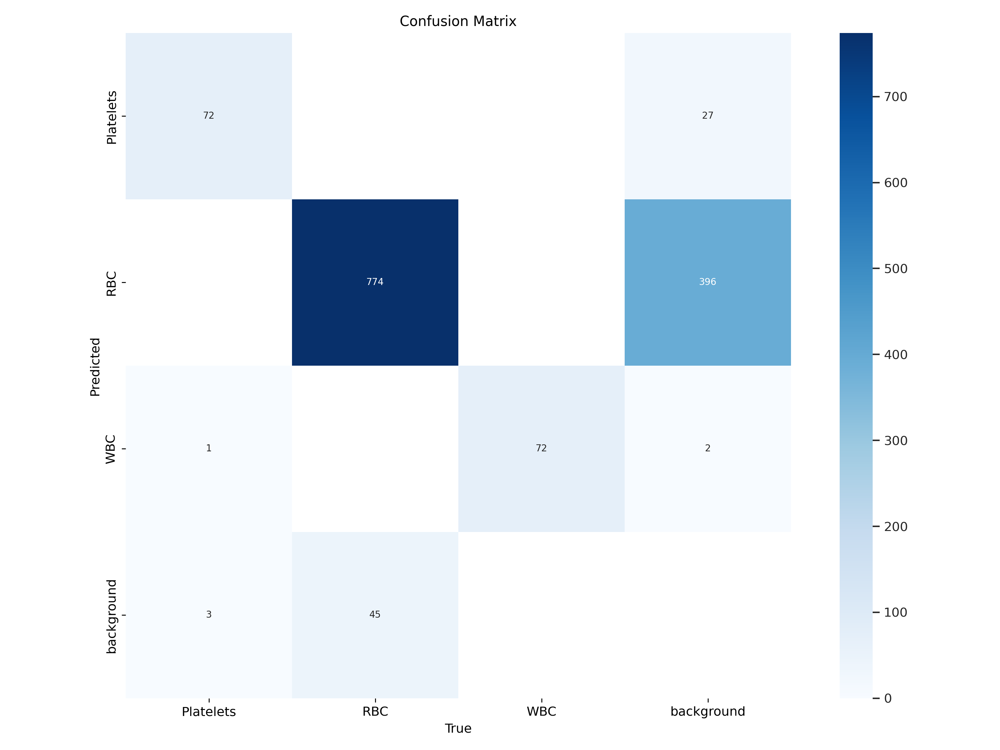

In [ ]:
Image(filename='/content/drive/MyDrive/Test_YOLO/BCCD2/confusion_matrix.png', width=1000)

## Ejecutar inferencia con pesos entrenados
Ejecute la inferencia con un punto de control entrenado previamente en el contenido de la carpeta de prueba/imágenes descargada de Roboflow.

In [ ]:
%cd /content/yolov5/
!python detect.py --weights runs/train/yolov5s_results/weights/best.pt --img 416 --conf 0.4 --source /content/BCCD/test/images

/content/yolov5
detect: weights=['runs/train/yolov5s_results/weights/best.pt'], source=/content/BCCD/test/images, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False
YOLOv5 🚀 v6.1-356-g4d8d84b Python-3.7.13 torch-1.12.0+cu113 CUDA:0 (Tesla T4, 15110MiB)

Fusing layers... 
custom_YOLOv5s summary: 232 layers, 7251912 parameters, 0 gradients, 16.8 GFLOPs
image 1/36 /content/BCCD/test/images/BloodImage_00038_jpg.rf.63d04b5c9db95f32fa7669f72e4903ca.jpg: 320x416 2 Plateletss, 22 RBCs, 1 WBC, Done. (0.013s)
image 2/36 /content/BCCD/test/images/BloodImage_00044_jpg.rf.589ee3d351cb6d9a3f7b7a942da5370a.jpg: 320x416 2 Plateletss, 18 RBCs, 2 WBCs, Done. (0.009s)
image 3/36 /c

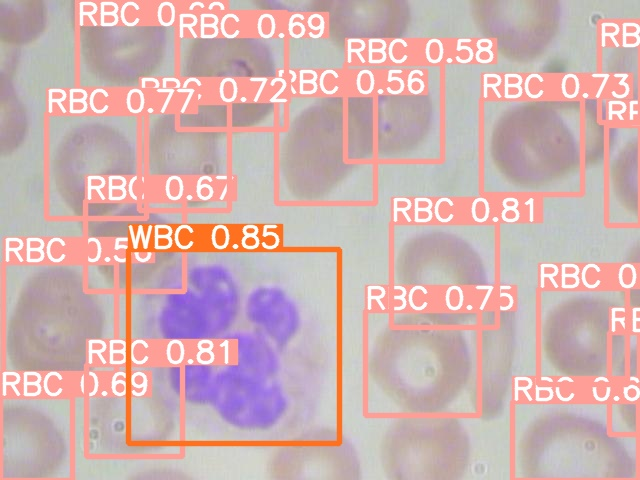

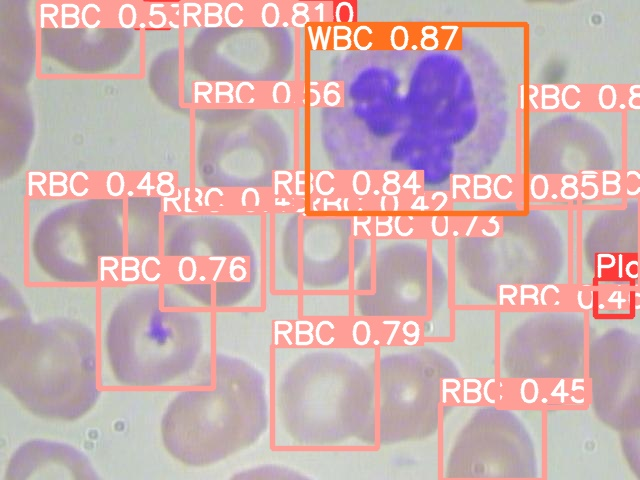

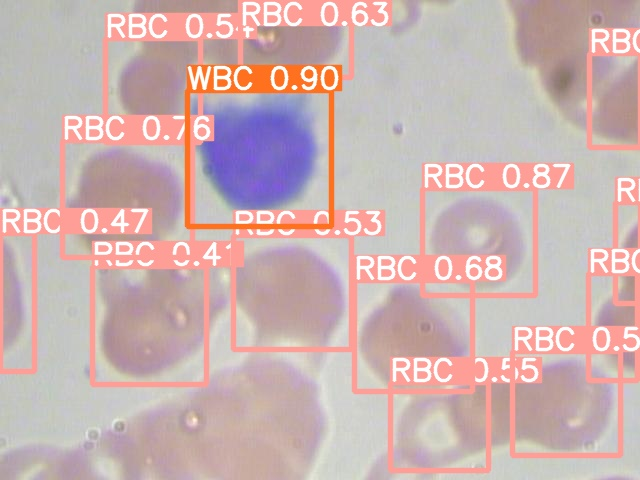

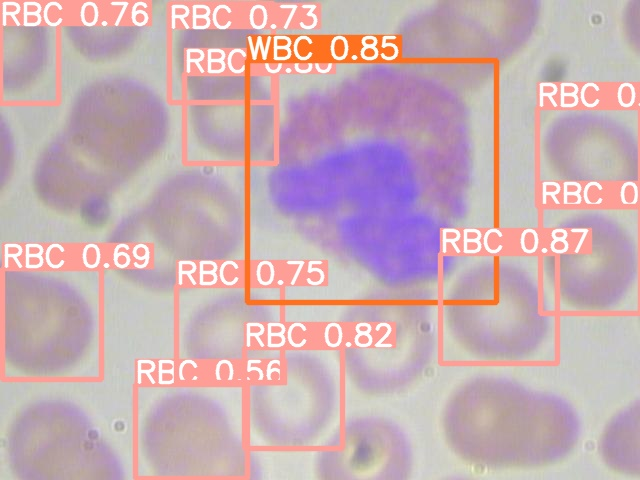

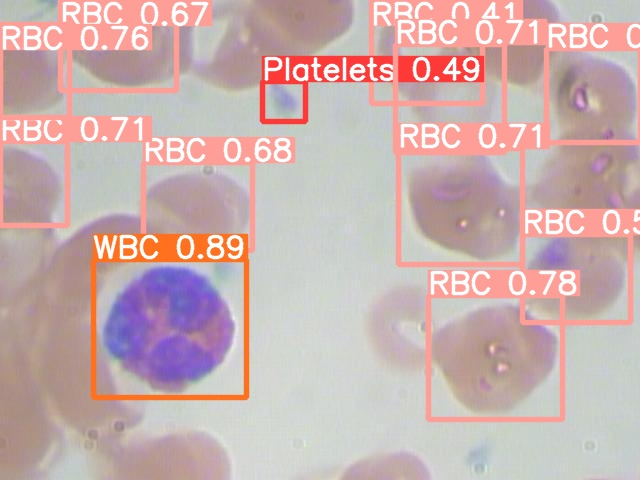

...

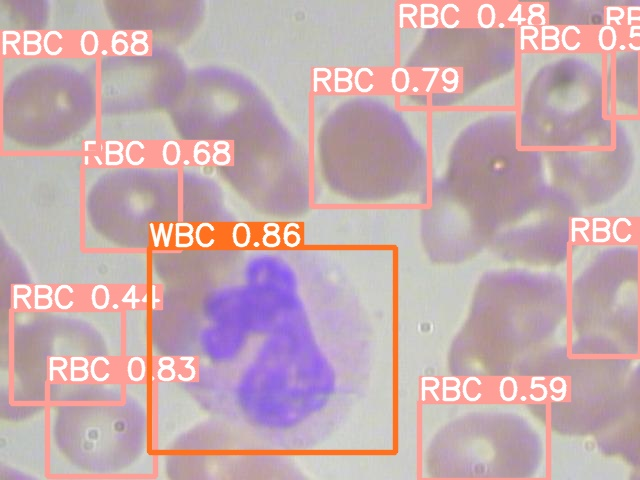

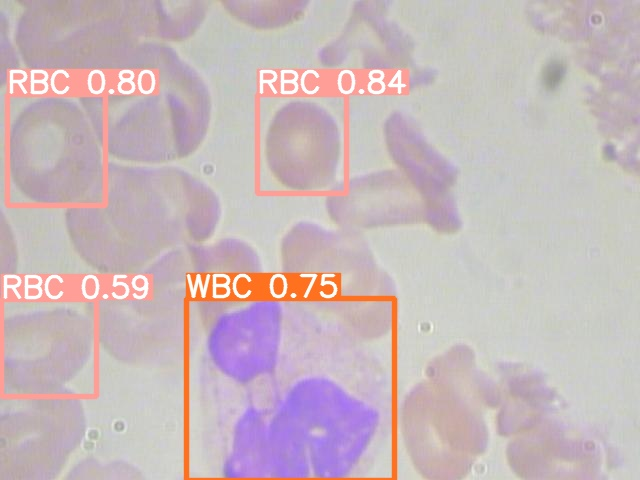

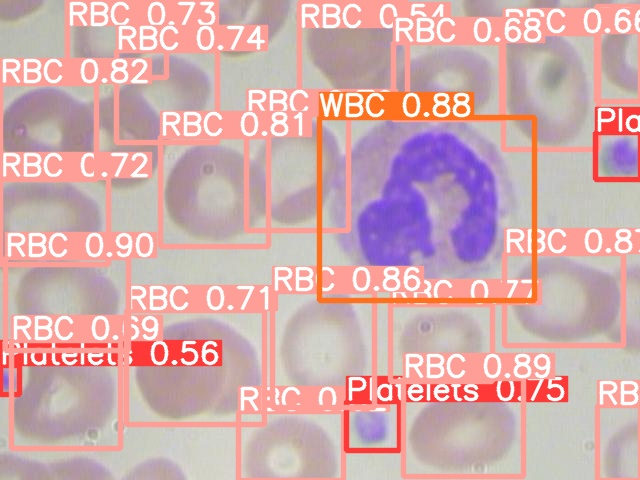

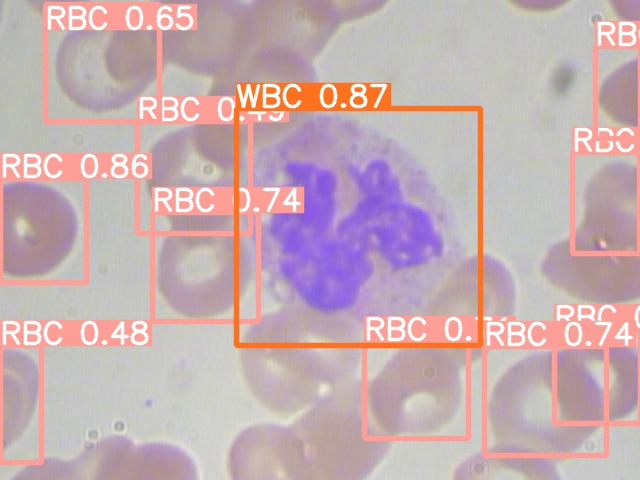

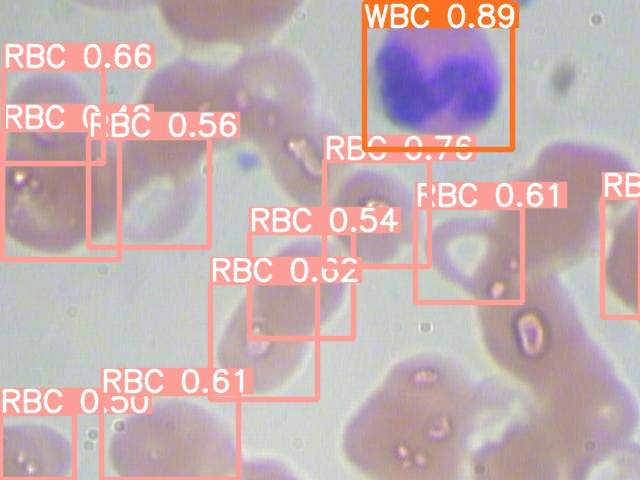

In [ ]:
import glob
from IPython.display import Image, display
for imageName in glob.glob('/content/yolov5/runs/detect/exp/*.jpg'):
  display(Image(filename=imageName))
  print("\n")